## Data Preprocessing with Scanpy

In [1]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from marrow droplet folder(s) into an AnnData object

In [3]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Marrow-10X_P7_2"),
# sc.read_10x_mtx("droplet/Marrow-10X_P7_3"),

# checking how visualizations look when marrow_droplet_annotation.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Marrow-10X_P7_2"),
    sc.read_10x_mtx("../droplet/Marrow-10X_P7_3"),
])

tiss.obs_names_make_unique()

tiss.obs


    reading ../droplet/Marrow-10X_P7_2/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Marrow-10X_P7_3/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


""
AAACCTGCAGTAACGG-1
AAACGGGAGAAGAAGC-1
AAACGGGAGACCGGAT-1
AAACGGGAGCGCTCCA-1
AAACGGGAGGACGAAA-1
...
TTTGTCAAGGCAGTCA-1
TTTGTCAAGTGTTTGC-1
TTTGTCAGTCGCGGTT-1
TTTGTCATCCGCATAA-1


In [4]:
tiss.obs

""
AAACCTGCAGTAACGG-1
AAACGGGAGAAGAAGC-1
AAACGGGAGACCGGAT-1
AAACGGGAGCGCTCCA-1
AAACGGGAGGACGAAA-1
...
TTTGTCAAGGCAGTCA-1
TTTGTCAAGTGTTTGC-1
TTTGTCAGTCGCGGTT-1
TTTGTCATCCGCATAA-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [5]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

filtered out 460 cells that have less than 500 genes expressed


,n_genes,n_counts
AAACCTGCAGTAACGG-1,2302,8092.0
AAACGGGAGACCGGAT-1,1502,4437.0
AAACGGGAGCGCTCCA-1,1704,7139.0
AAACGGGAGGACGAAA-1,2627,17379.0
AAACGGGAGGTACTCT-1,3184,12895.0
...,...,...
TTTGTCAAGCGCTCCA-1,3320,14435.0
TTTGTCAAGGCAGTCA-1,578,6492.0
TTTGTCAAGTGTTTGC-1,2694,19103.0
TTTGTCATCCGCATAA-1,2045,8392.0


## Normalization

In [6]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [7]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


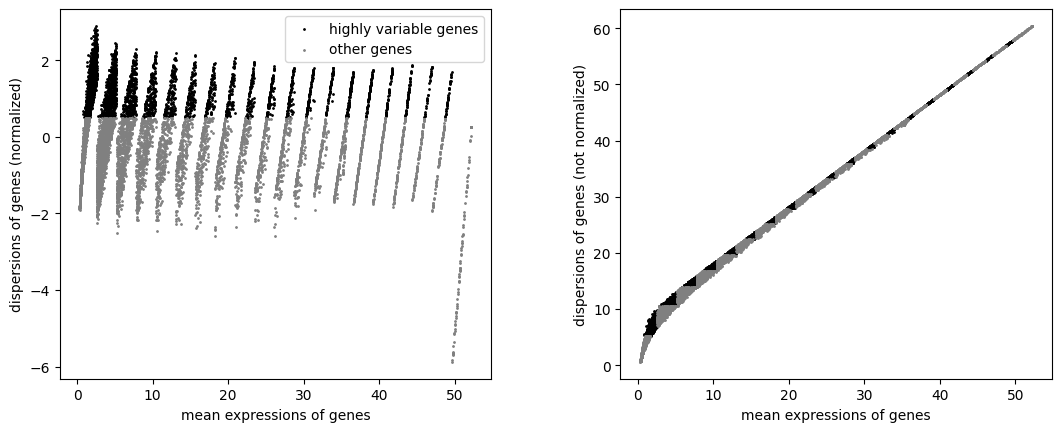

In [8]:
sc.pl.highly_variable_genes(tiss)

In [9]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
Fam150a,0.000980,0.034844,True,35.628116,43.831144,0.507652
Ppp1r42,0.107429,0.328437,True,1.528304,5.761998,0.794450
A830018L16Rik,0.000322,0.014250,True,44.134067,52.337097,1.538518
Lactb2,0.051583,0.184818,True,1.928822,6.301165,1.076546
Eya1,0.011493,0.097740,True,7.038316,14.562577,1.083355
...,...,...,...,...,...,...
Tlr7,0.057019,0.233081,True,2.063942,6.858449,1.368120
Arhgap6,0.024009,0.150647,True,4.842603,11.559385,1.293075
Asmt,0.000154,0.006582,True,36.019628,44.125042,0.896745
Tmlhe,0.001568,0.035111,True,25.794578,33.974222,1.417154


## Dimensionality Reduction
Through PCA

In [10]:
# PCA
sc.pp.pca(tiss)


computing PCA
    with n_comps=50
    finished (0:00:01)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


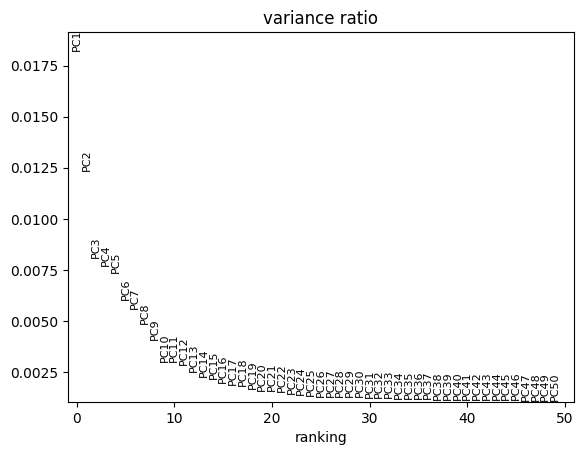

In [11]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [12]:
marrow_annotations = pd.read_csv("../annotations/Marrow_droplet_annotation.csv")

y = marrow_annotations["cell_ontology_class"].values
y


array(['monocyte', 'T cell', 'T cell', ..., 'granulocytopoietic cell',
       'proerythroblast', 'proerythroblast'], shape=(3652,), dtype=object)

In [13]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

,n_genes,n_counts,cell_ontology_class
AAACCTGCAGTAACGG-1,2302,8092.0,monocyte
AAACGGGAGACCGGAT-1,1502,4437.0,T cell
AAACGGGAGCGCTCCA-1,1704,7139.0,T cell
AAACGGGAGGACGAAA-1,2627,17379.0,granulocytopoietic cell
AAACGGGAGGTACTCT-1,3184,12895.0,promonocyte
...,...,...,...
TTTGTCAAGCGCTCCA-1,3320,14435.0,basophil
TTTGTCAAGGCAGTCA-1,578,6492.0,erythroblast
TTTGTCAAGTGTTTGC-1,2694,19103.0,granulocytopoietic cell
TTTGTCATCCGCATAA-1,2045,8392.0,proerythroblast


## Clustering


In [14]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=0.4) 

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed connectivities (0:00:02)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 13 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


In [15]:
#inspection based on above ouptput
tiss.obs

,n_genes,n_counts,cell_ontology_class,louvain
AAACCTGCAGTAACGG-1,2302,8092.0,monocyte,1
AAACGGGAGACCGGAT-1,1502,4437.0,T cell,8
AAACGGGAGCGCTCCA-1,1704,7139.0,T cell,8
AAACGGGAGGACGAAA-1,2627,17379.0,granulocytopoietic cell,2
AAACGGGAGGTACTCT-1,3184,12895.0,promonocyte,4
...,...,...,...,...
TTTGTCAAGCGCTCCA-1,3320,14435.0,basophil,3
TTTGTCAAGGCAGTCA-1,578,6492.0,erythroblast,10
TTTGTCAAGTGTTTGC-1,2694,19103.0,granulocytopoietic cell,2
TTTGTCATCCGCATAA-1,2045,8392.0,proerythroblast,6


## Visualizing Clusters Using tSNE

computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3652 samples in 0.001s...
[t-SNE] Computed neighbors for 3652 samples in 0.058s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3652
[t-SNE] Computed conditional probabilities for sample 2000 / 3652
[t-SNE] Computed conditional probabilities for sample 3000 / 3652
[t-SNE] Computed conditional probabilities for sample 3652 / 3652
[t-SNE] Mean sigma: 1.261116
[t-SNE] KL divergence after 250 iterations with early exaggeration: 66.848587
[t-SNE] KL divergence after 1000 iterations: 0.840837
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:06)


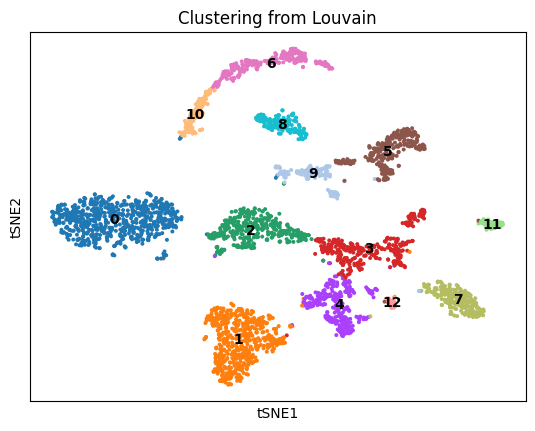

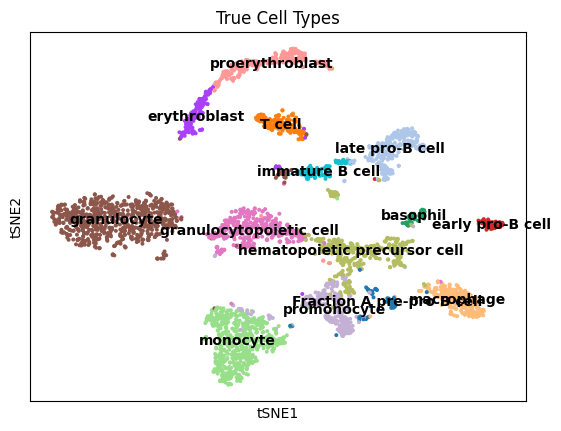

In [16]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clustering from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((2921, 4688), (731, 4688), (2921,), (731,))

## scikit-learn Machine Learning Classifiers

In [18]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [20]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

📌 Model: Logistic Regression
✅ Accuracy: 0.9590

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83        13
           1       0.96      1.00      0.98        26
           2       0.86      0.86      0.86        14
           3       1.00      1.00      1.00        15
           4       0.96      0.96      0.96        23
           5       0.97      0.99      0.98       150
           6       0.95      0.97      0.96        73
           7       0.95      0.92      0.93        75
           8       1.00      0.91      0.95        34
           9       0.93      1.00      0.96        50
          10       1.00      0.96      0.98        45
          11       0.96      0.98      0.97       111
          12       1.00      0.98      0.99        50
          13       0.90      0.87      0.88        52

    accuracy                           0.96       731
   macro avg       0.95      0.94      0.95       731
weighted

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Random Forest
✅ Accuracy: 0.9384

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.31      0.47        13
           1       0.84      1.00      0.91        26
           2       1.00      0.64      0.78        14
           3       1.00      0.93      0.97        15
           4       0.95      0.91      0.93        23
           5       0.97      0.98      0.98       150
           6       0.96      0.97      0.97        73
           7       0.91      0.93      0.92        75
           8       1.00      0.85      0.92        34
           9       0.85      1.00      0.92        50
          10       0.98      1.00      0.99        45
          11       0.93      1.00      0.96       111
          12       1.00      0.98      0.99        50
          13       0.87      0.77      0.82        52

    accuracy                           0.94       731
   macro avg       0.95      0.88      0.89       731
weighted avg  

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Pytorch Neural Network

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [22]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [23]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


Epoch 1, Loss: 2.4149
Epoch 2, Loss: 1.8114
Epoch 3, Loss: 1.2445
Epoch 4, Loss: 0.6852
Epoch 5, Loss: 0.3634
Epoch 6, Loss: 0.2313
Epoch 7, Loss: 0.1635
Epoch 8, Loss: 0.1242
Epoch 9, Loss: 0.1008
Epoch 10, Loss: 0.0859


In [25]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()

acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


📌 Model: Neural Network
✅ Accuracy: 0.9261

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.69      0.72        13
           1       0.89      0.96      0.93        26
           2       0.92      0.86      0.89        14
           3       0.00      0.00      0.00        15
           4       0.95      0.91      0.93        23
           5       0.97      0.99      0.98       150
           6       0.99      0.97      0.98        73
           7       0.86      0.93      0.90        75
           8       0.97      0.91      0.94        34
           9       0.82      1.00      0.90        50
          10       0.92      1.00      0.96        45
          11       0.94      0.95      0.95       111
          12       1.00      0.96      0.98        50
          13       0.87      0.77      0.82        52

    accuracy                           0.93       731
   macro avg       0.85      0.85      0.85       731
weighted avg 

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Visualizing Model Results using TSNE

In [26]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [27]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [28]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering


/var/folders/wk/gl6vb2s945jbqmt08f1p2pdw0000gn/T/ipykernel_48235/845363431.py:7: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tiss, resolution=3.5)


    finished: found 39 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3652 samples in 0.001s...
[t-SNE] Computed neighbors for 3652 samples in 0.057s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3652
[t-SNE] Computed conditional probabilities for sample 2000 / 3652
[t-SNE] Computed conditional probabilities for sample 3000 / 3652
[t-SNE] Computed conditional probabilities for sample 3652 / 3652
[t-SNE] Mean sigma: 1.261116
[t-SNE] KL divergence after 250 iterations with early exaggeration: 66.848587
[t-SNE] KL divergence after 1000 iterations: 0.840837
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:05)


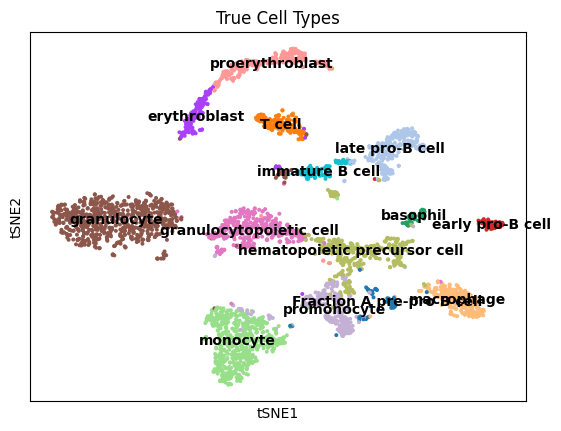

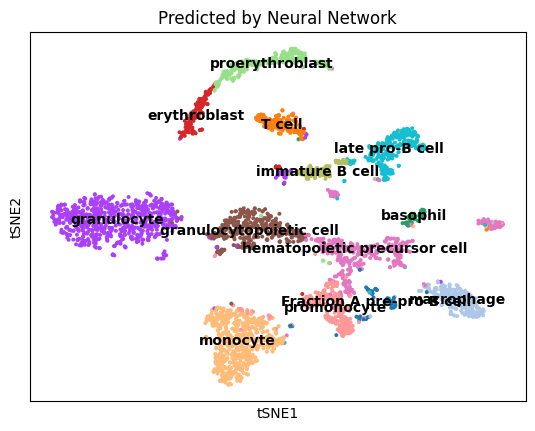

In [29]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


In [30]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")


TypeError: Categoricals can only be compared if 'categories' are the same.